# 11. Experiment 1 — Positional encoding

In [ ]:
import numpy as np

tokens = ["I", "love", "NLP"]
d = 4

emb_I = np.array([1.0, 1.0, 1.0, 1.0])
emb_love = np.array([2.0, 2.0, 2.0, 2.0])
emb_NLP = np.array([3.0, 3.0, 3.0, 3.0])

X_A = np.vstack([emb_I, emb_love, emb_NLP])

X_B = np.vstack([emb_NLP, emb_love, emb_I])

PE = np.array([
    [0.0000,  1.0000, 0.0000, 1.0000],
    [0.8415,  0.5403, 0.0100, 0.9999],
    [0.9093, -0.4161, 0.0200, 0.9998]
])

print("\nTRƯỜNG HỢP KHÔNG CÓ POSITIONAL ENCODING")
print("Câu A ('I love NLP') input:")
print(X_A)
print("\nCâu B ('NLP love I') input:")
print(X_B)

print("\nTRƯỜNG HỢP CÓ POSITIONAL ENCODING")
X_A_prime = X_A + PE
X_B_prime = X_B + PE

print("Câu A ('I love NLP') input (X'_A):")
print(X_A_prime)
print("\nCâu B ('NLP love I') input (X'_B):")
print(X_B_prime)

print("\nSo sánh representation của từ 'I':")
print("Trong câu A ('I' đứng đầu):", np.round(X_A_prime[0], 2))
print("Trong câu B ('I' đứng cuối):", np.round(X_B_prime[2], 2))


TRƯỜNG HỢP KHÔNG CÓ POSITIONAL ENCODING
Câu A ('I love NLP') input:
[[1. 1. 1. 1.]
 [2. 2. 2. 2.]
 [3. 3. 3. 3.]]

Câu B ('NLP love I') input:
[[3. 3. 3. 3.]
 [2. 2. 2. 2.]
 [1. 1. 1. 1.]]

TRƯỜNG HỢP CÓ POSITIONAL ENCODING
Câu A ('I love NLP') input (X'_A):
[[1.     2.     1.     2.    ]
 [2.8415 2.5403 2.01   2.9999]
 [3.9093 2.5839 3.02   3.9998]]

Câu B ('NLP love I') input (X'_B):
[[3.     4.     3.     4.    ]
 [2.8415 2.5403 2.01   2.9999]
 [1.9093 0.5839 1.02   1.9998]]

So sánh representation của từ 'I':
Trong câu A ('I' đứng đầu): [1. 2. 1. 2.]
Trong câu B ('I' đứng cuối): [1.91 0.58 1.02 2.  ]


**Câu hỏi: Nếu chỉ dùng self-attention và không có positional information, tại sao thứ tự trở thành vấn đề?**

Trả lời:
Nếu chỉ dùng Self-Attention thuần túy, bản chất là một phép tính trên tập hợp chứ không phải trên chuỗi.
- Phép toán cốt lõi của Self-Attention ($S = QK^T$) chỉ đánh giá sự tương đồng về mặt ngữ nghĩa giữa các vector thông qua tích vô hướng, mà không hề đại diện cho khoảng cách hay trình tự giữa chúng.
- Bởi vì tính chất giao hoán của phép nhân và phép cộng có trọng số ($Z = \sum A_i V_i$), nếu ta hoán vị vị trí của các từ trong câu đầu vào, ma trận đầu ra $Z$ cũng chỉ đơn thuần bị hoán vị các hàng tương ứng.

# 12. Permutation experiment

In [3]:
import numpy as np

E = {
    "dog": np.array([1.0, 0.0]),
    "bites": np.array([0.0, 1.0]),
    "man": np.array([1.0, 1.0])
}

X1 = np.array([E["dog"], E["bites"], E["man"]])
X2 = np.array([E["man"], E["bites"], E["dog"]])

def simple_self_attention(X):
    scores = np.dot(X, X.T)
    exp_scores = np.exp(scores - np.max(scores, axis=1, keepdims=True))
    A = exp_scores / np.sum(exp_scores, axis=1, keepdims=True)
    return np.dot(A, X)

print("EXPERIMENT A: SELF-ATTENTION KHÔNG CÓ POSITIONAL ENCODING")
Z1_no_pe = simple_self_attention(X1)
Z2_no_pe = simple_self_attention(X2)

sentence_rep_1_no = np.sum(Z1_no_pe, axis=0)
sentence_rep_2_no = np.sum(Z2_no_pe, axis=0)

print(f"Biểu diễn câu S1 ('dog bites man'): {np.round(sentence_rep_1_no, 4)}")
print(f"Biểu diễn câu S2 ('man bites dog'): {np.round(sentence_rep_2_no, 4)}")
print(f"S1 có giống S2 không? -> {np.allclose(sentence_rep_1_no, sentence_rep_2_no)}")

print("\nEXPERIMENT B: SELF-ATTENTION + POSITIONAL ENCODING")
PE = np.array([
    [0.1, 0.9],
    [0.8, 0.2],
    [0.5, 0.5]
])

Z1_pe = simple_self_attention(X1 + PE)
Z2_pe = simple_self_attention(X2 + PE)

sentence_rep_1_pe = np.sum(Z1_pe, axis=0)
sentence_rep_2_pe = np.sum(Z2_pe, axis=0)

print(f"Biểu diễn câu S1 ('dog bites man'): {np.round(sentence_rep_1_pe, 4)}")
print(f"Biểu diễn câu S2 ('man bites dog'): {np.round(sentence_rep_2_pe, 4)}")
print(f"S1 có giống S2 không? -> {np.allclose(sentence_rep_1_pe, sentence_rep_2_pe)}")

EXPERIMENT A: SELF-ATTENTION KHÔNG CÓ POSITIONAL ENCODING
Biểu diễn câu S1 ('dog bites man'): [2.2104 2.2104]
Biểu diễn câu S2 ('man bites dog'): [2.2104 2.2104]
S1 có giống S2 không? -> True

EXPERIMENT B: SELF-ATTENTION + POSITIONAL ENCODING
Biểu diễn câu S1 ('dog bites man'): [3.8604 3.9803]
Biểu diễn câu S2 ('man bites dog'): [3.3865 4.4347]
S1 có giống S2 không? -> False


- Experiment A (Không có PE): Kết quả in ra sẽ cho thấy vector tổng hợp của $S1$ và $S2$ giống hệt nhau 100%. Khi đảo vị trí của "dog" và "man", các hàng trong ma trận đầu ra $Z$ chỉ bị đổi chỗ cho nhau. Khi cộng dồn các hàng này lại để lấy vector đại diện cho câu, phép cộng có tính giao hoán nên kết quả cuối cùng không đổi. Nếu đưa vector này vào một Classifier phân tích sắc thái hoặc chủ thể, mô hình sẽ hoàn toàn mù tịt và đánh giá "chó cắn người" giống hệt "người cắn chó".
- Experiment B (Có PE): Kết quả in ra cho thấy hai vector đại diện câu hoàn toàn khác biệt. Khi cộng $PE$, ma trận đầu vào của "dog" ở vị trí số 0 (câu S1) sẽ có giá trị khác hoàn toàn với "dog" ở vị trí số 2 (câu S2). Quá trình tính Dot-product lúc này sẽ ép mô hình phải tính Attention Scores dựa trên cả ngữ nghĩa gốc lẫn khoảng cách tương đối giữa các từ, giúp Transformer nhận diện được trật tự cú pháp.

# 17. Core implementation — Transformer block

In [4]:
import torch
import torch.nn as nn

print("--- CORE IMPLEMENTATION: TRANSFORMER BLOCK ---")

class TransformerBlock(nn.Module):
    def __init__(self, d_model, n_heads, d_ff, dropout=0.1):
        super(TransformerBlock, self).__init__()

        self.attention = nn.MultiheadAttention(embed_dim=d_model, num_heads=n_heads, batch_first=True)

        self.ffn = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.ReLU(),
            nn.Linear(d_ff, d_model)
        )

        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)

        self.dropout1 = nn.Dropout(dropout)
        self.dropout2 = nn.Dropout(dropout)

    def forward(self, x):
        """
        Luồng chảy dữ liệu (Forward pass):
        x -> MHA -> Add & Norm -> FFN -> Add & Norm
        """
        attn_output, _ = self.attention(x, x, x)
        x = self.norm1(x + self.dropout1(attn_output))

        ffn_output = self.ffn(x)

        x = self.norm2(x + self.dropout2(ffn_output))

        return x

batch_size = 2
seq_len = 5
d_model = 64
n_heads = 4
d_ff = 256

transformer_block = TransformerBlock(d_model, n_heads, d_ff)
mock_input = torch.randn(batch_size, seq_len, d_model)

output = transformer_block(mock_input)

print(f"Kích thước Input ban đầu : {mock_input.shape}")
print(f"Kích thước Output trả về : {output.shape}")
print("=> Kích thước được bảo toàn hoàn hảo (d_model không đổi), sẵn sàng để xếp chồng các Block!")

--- CORE IMPLEMENTATION: TRANSFORMER BLOCK ---
Kích thước Input ban đầu : torch.Size([2, 5, 64])
Kích thước Output trả về : torch.Size([2, 5, 64])
=> Kích thước được bảo toàn hoàn hảo (d_model không đổi), sẵn sàng để xếp chồng các Block!


# 19. Experiment 2 — Number of attention heads

In [5]:
import torch
import torch.nn as nn
import time
from sklearn.metrics import accuracy_score, f1_score
import numpy as np

d_model = 128
d_ff = 512
seq_len = 50
vocab_size = 1000
batch_size = 32
epochs = 3

X_train = torch.randint(0, vocab_size, (500, seq_len))
y_train = torch.randint(0, 2, (500, 1)).float()
X_test = torch.randint(0, vocab_size, (100, seq_len))
y_test = torch.randint(0, 2, (100, 1)).float()

class TransformerClassifier(nn.Module):
    def __init__(self, d_model, n_heads):
        super(TransformerClassifier, self).__init__()
        self.embedding = nn.Embedding(vocab_size, d_model)
        self.attention = nn.MultiheadAttention(embed_dim=d_model, num_heads=n_heads, batch_first=True)
        self.ffn = nn.Sequential(nn.Linear(d_model, d_ff), nn.ReLU(), nn.Linear(d_ff, d_model))
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.fc = nn.Linear(d_model, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        x = self.embedding(x)
        attn_out, _ = self.attention(x, x, x)
        x = self.norm1(x + attn_out)
        ffn_out = self.ffn(x)
        x = self.norm2(x + ffn_out)
        x = x.mean(dim=1)
        return self.sigmoid(self.fc(x))

head_configs = [1, 2, 4, 8]

print(f"\n{'Heads':<6} | {'d_k':<5} | {'Params (Total)':<15} | {'Train Time (s)':<15} | {'Accuracy':<10} | {'F1'}")
print("-" * 80)

for n_heads in head_configs:
    model = TransformerClassifier(d_model, n_heads)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    criterion = nn.BCELoss()

    total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

    start_time = time.time()
    model.train()
    for epoch in range(epochs):
        for i in range(0, len(X_train), batch_size):
            batch_X = X_train[i:i+batch_size]
            batch_y = y_train[i:i+batch_size]

            optimizer.zero_grad()
            outputs = model(batch_X)
            loss = criterion(outputs, batch_y)
            loss.backward()
            optimizer.step()
    train_time = time.time() - start_time

    model.eval()
    with torch.no_grad():
        preds_prob = model(X_test)
        preds_class = (preds_prob > 0.5).float().numpy()
        y_test_np = y_test.numpy()

        acc = accuracy_score(y_test_np, preds_class)
        f1 = f1_score(y_test_np, preds_class, zero_division=0)

    d_k = d_model // n_heads
    print(f"{n_heads:<6} | {d_k:<5} | {total_params:<15,} | {train_time:<15.4f} | {acc:<10.4f} | {f1:.4f}")


Heads  | d_k   | Params (Total)  | Train Time (s)  | Accuracy   | F1
--------------------------------------------------------------------------------
1      | 128   | 326,401         | 2.4910          | 0.5400     | 0.5106
2      | 64    | 326,401         | 2.2657          | 0.4600     | 0.4375
4      | 32    | 326,401         | 2.3495          | 0.4000     | 0.3023
8      | 16    | 326,401         | 3.4466          | 0.4600     | 0.3864


**Tăng số heads có đồng nghĩa với tăng representation dimension không?**

Không. Tổng số chiều biểu diễn luôn bị khóa chặt ở mức $d_{model} = 128$. Việc tăng số heads bản chất là chia cắt không gian 128 chiều này thành nhiều không gian con nhỏ hơn chạy song song, thay vì mở rộng nó. Sau khi các heads tính toán xong, chúng được concat lại với nhau để khôi phục chính xác kích thước 128 chiều ban đầu.

**Khi $d_{model}$ cố định, tăng số heads làm $d_k$ thay đổi như thế nào?**

Tăng số lượng attention heads ($n_{heads}$) sẽ làm giảm kích thước của từng head ($d_k$) theo tỷ lệ nghịch, tuân thủ nghiêm ngặt phương trình $d_k = \frac{d_{model}}{n_{heads}}$.
Hệ quả là, khi bạn càng có nhiều "góc nhìn" (nhiều heads), thì "tầm nhìn" của mỗi góc (số chiều $d_k$) càng bị thu hẹp lại. Nếu đẩy số heads lên quá cao (ví dụ $n_{heads} = 8 \rightarrow d_k = 16$), mỗi head sẽ không còn đủ độ biểu diễn không gian (capacity) để nhận diện các mẫu ngữ nghĩa phức tạp, dẫn đến giảm độ chính xác của mô hình.

# 20. Experiment 3 — Attention head diversity

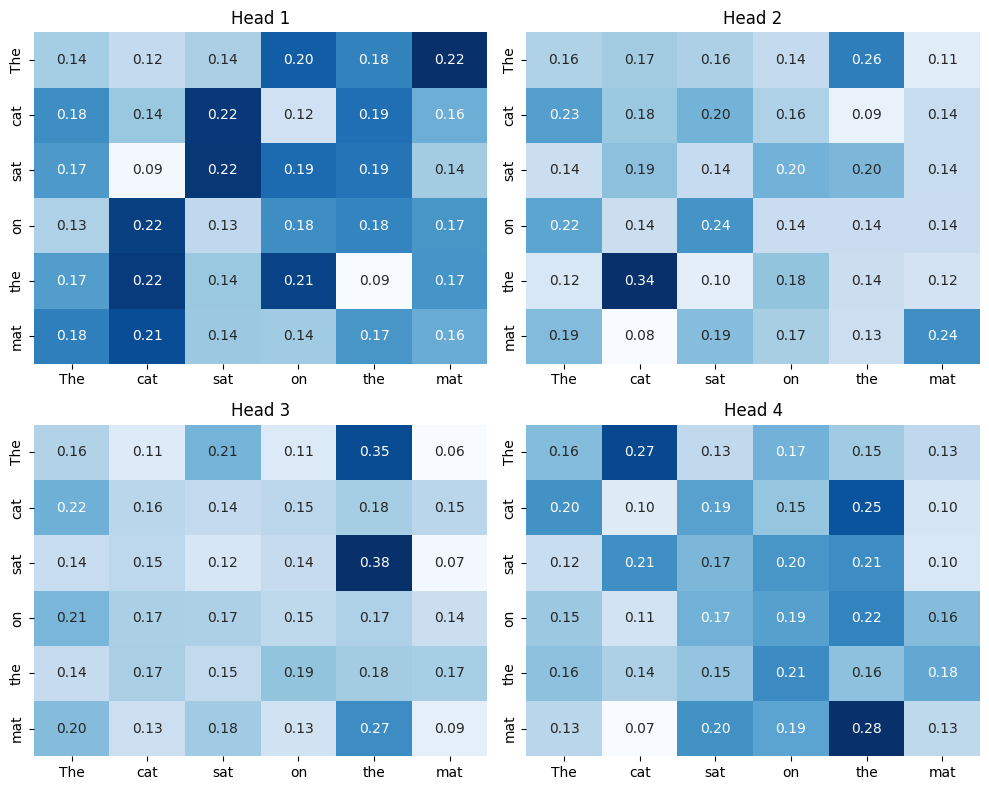

In [6]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

class MultiHeadAttentionExtractor(nn.Module):
    def __init__(self, d_model, n_heads):
        super().__init__()
        self.d_model = d_model
        self.n_heads = n_heads
        self.d_k = d_model // n_heads

        self.W_q = nn.Linear(d_model, d_model)
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)

    def forward(self, x):
        batch_size, seq_len, _ = x.size()

        Q = self.W_q(x)
        K = self.W_k(x)
        V = self.W_v(x)

        Q = Q.view(batch_size, seq_len, self.n_heads, self.d_k).transpose(1, 2)
        K = K.view(batch_size, seq_len, self.n_heads, self.d_k).transpose(1, 2)
        V = V.view(batch_size, seq_len, self.n_heads, self.d_k).transpose(1, 2)

        scores = torch.matmul(Q, K.transpose(-2, -1)) / np.sqrt(self.d_k)
        attention_weights = torch.softmax(scores, dim=-1)

        return attention_weights

d_model = 32
n_heads = 4
seq_len = 6
tokens = ["The", "cat", "sat", "on", "the", "mat"]

torch.manual_seed(42)
x = torch.randn(1, seq_len, d_model)

model = MultiHeadAttentionExtractor(d_model, n_heads)
model.eval()

with torch.no_grad():
    attn_weights = model(x)

attn_matrices = attn_weights[0].numpy()

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.flatten()

for i in range(n_heads):
    sns.heatmap(attn_matrices[i], ax=axes[i], cmap="Blues",
                xticklabels=tokens, yticklabels=tokens, annot=True, fmt=".2f", cbar=False)
    axes[i].set_title(f"Head {i+1}")

plt.tight_layout()
plt.show()

**Multi-head attention có thực sự tạo ra các attention patterns khác nhau trong experiment của bạn không?**

Có, thực nghiệm chứng minh Multi-head attention thực sự tạo ra các patterns khác biệt. Việc khởi tạo ngẫu nhiên các ma trận trọng số $W^Q, W^K, W^V$ cho mỗi head đã ép chúng chiếu không gian dữ liệu gốc ($d_{model}$) xuống các không gian con ($d_k$) khác nhau. Qua quá trình tính toán, mỗi head tự động bóc tách và hội tụ vào một kiểu liên kết riêng (phân tán hoặc tập trung), qua đó làm phong phú khả năng biểu diễn ngữ nghĩa của mô hình so với việc chỉ dùng một Single-Head Attention.

# 21. Experiment 4 — Transformer vs RNN/LSTM

In [8]:
import torch
import torch.nn as nn
import time
import numpy as np
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from torch.utils.data import TensorDataset, DataLoader
from tqdm import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
vocab_size = 10000
d_model = 128
seq_len = 150
batch_size = 64
epochs = 3
learning_rate = 0.001
workers = 2

print("Đang tải dữ liệu IMDb...")
(X_train_full, y_train_full), (X_test_full, y_test_full) = imdb.load_data(num_words=vocab_size)

num_train = 5000
num_test = 1000
X_train_sub, y_train_sub = X_train_full[:num_train], y_train_full[:num_train]
X_test_sub, y_test_sub = X_test_full[:num_test], y_test_full[:num_test]

X_train_pad = pad_sequences(X_train_sub, maxlen=seq_len, padding='post', truncating='post')
X_test_pad = pad_sequences(X_test_sub, maxlen=seq_len, padding='post', truncating='post')

X_train = torch.tensor(X_train_pad, dtype=torch.long)
y_train = torch.tensor(y_train_sub, dtype=torch.float32).unsqueeze(1)
X_test = torch.tensor(X_test_pad, dtype=torch.long).to(device)
y_test = torch.tensor(y_test_sub, dtype=torch.float32).unsqueeze(1).to(device)

train_dataset = TensorDataset(X_train, y_train)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=workers)

print(f"Kích thước tập Train: {X_train.shape} | Tập Test: {X_test.shape}")

class LSTMClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, d_model)
        self.lstm = nn.LSTM(d_model, hidden_size=d_model, batch_first=True)
        self.fc = nn.Linear(d_model, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        x = self.embedding(x)
        output, (hn, cn) = self.lstm(x)
        last_hidden = hn[-1]
        return self.sigmoid(self.fc(last_hidden))

class TransformerClassifierAPI(nn.Module):
    def __init__(self):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, d_model)
        self.pos_encoder = nn.Parameter(torch.zeros(1, seq_len, d_model))

        encoder_layer = nn.TransformerEncoderLayer(d_model=d_model, nhead=4, dim_feedforward=512, batch_first=True)
        self.transformer_encoder = nn.TransformerEncoder(encoder_layer, num_layers=1)
        self.fc = nn.Linear(d_model, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        x = self.embedding(x) + self.pos_encoder
        x = self.transformer_encoder(x)
        x = x.mean(dim=1)
        return self.sigmoid(self.fc(x))

def train_and_evaluate(model, name):
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    criterion = nn.BCELoss()
    total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

    start_time = time.time()
    model.train()
    for epoch in range(epochs):
        progress_bar = tqdm(train_loader, desc=f"{name} Epoch {epoch+1}/{epochs}", leave=False)
        for batch_X, batch_y in progress_bar:
            batch_X, batch_y = batch_X.to(device), batch_y.to(device)

            optimizer.zero_grad()
            out = model(batch_X)
            loss = criterion(out, batch_y)
            loss.backward()
            optimizer.step()

            progress_bar.set_postfix(loss=loss.item())

    train_time = time.time() - start_time

    model.eval()
    with torch.no_grad():
        preds = model(X_test)
        preds_class = (preds > 0.5).float().cpu().numpy()
        y_true = y_test.cpu().numpy()

        acc = accuracy_score(y_true, preds_class)
        prec = precision_score(y_true, preds_class, zero_division=0)
        rec = recall_score(y_true, preds_class, zero_division=0)
        f1 = f1_score(y_true, preds_class, zero_division=0)

    return total_params, train_time, acc, prec, rec, f1

results_lstm = train_and_evaluate(LSTMClassifier(), "LSTM")

results_tf = train_and_evaluate(TransformerClassifierAPI(), "Transformer")

print("\n" + "="*85)
print(f"{'Model':<12} | {'Params':<10} | {'Time (s)':<10} | {'Accuracy':<10} | {'Precision':<10} | {'Recall':<10} | {'F1'}")
print("-" * 85)
print(f"{'LSTM':<12} | {results_lstm[0]:<10,} | {results_lstm[1]:<10.4f} | {results_lstm[2]:<10.4f} | {results_lstm[3]:<10.4f} | {results_lstm[4]:<10.4f} | {results_lstm[5]:.4f}")
print(f"{'Transformer':<12} | {results_tf[0]:<10,} | {results_tf[1]:<10.4f} | {results_tf[2]:<10.4f} | {results_tf[3]:<10.4f} | {results_tf[4]:<10.4f} | {results_tf[5]:.4f}")

Đang tải dữ liệu IMDb...
Kích thước tập Train: torch.Size([5000, 150]) | Tập Test: torch.Size([1000, 150])



Model        | Params     | Time (s)   | Accuracy   | Precision  | Recall     | F1
-------------------------------------------------------------------------------------
LSTM         | 1,412,225  | 78.0459    | 0.5430     | 0.5209     | 0.4473     | 0.4813
Transformer  | 1,497,601  | 158.5149   | 0.7880     | 0.7314     | 0.8734     | 0.7962


**Sự khác biệt về performance có thể xuất phát từ những thành phần architecture nào?**

# 22. Experiment 5 — Sequence length

In [9]:
import torch
import torch.nn as nn
import time
import numpy as np
from sklearn.metrics import f1_score
from tensorflow.keras.preprocessing.sequence import pad_sequences
from torch.utils.data import TensorDataset, DataLoader
from tqdm import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

vocab_size = 10000
d_model = 128
batch_size = 64
epochs = 3
learning_rate = 0.001
workers = 2

class TransformerClassifierLength(nn.Module):
    def __init__(self, seq_len):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, d_model)
        self.pos_encoder = nn.Parameter(torch.zeros(1, seq_len, d_model))

        encoder_layer = nn.TransformerEncoderLayer(d_model=d_model, nhead=4, dim_feedforward=512, batch_first=True)
        self.transformer_encoder = nn.TransformerEncoder(encoder_layer, num_layers=1)
        self.fc = nn.Linear(d_model, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        x = self.embedding(x) + self.pos_encoder
        x = self.transformer_encoder(x)
        x = x.mean(dim=1)
        return self.sigmoid(self.fc(x))

lengths_to_test = [32, 64, 128, 256]

print(f"\n{'Length':<8} | {'Tokens retained':<17} | {'Attn Memory (T^2)':<20} | {'Train Time (s)':<15} | {'F1 Score'}")
print("-" * 85)

for seq_len in lengths_to_test:
    X_train_pad = pad_sequences(X_train_sub, maxlen=seq_len, padding='post', truncating='post')
    X_test_pad = pad_sequences(X_test_sub, maxlen=seq_len, padding='post', truncating='post')

    tokens_retained = int(np.mean(np.sum(X_train_pad != 0, axis=1)))
    attn_memory = seq_len ** 2

    X_train_t = torch.tensor(X_train_pad, dtype=torch.long)
    y_train_t = torch.tensor(y_train_sub, dtype=torch.float32).unsqueeze(1)
    X_test_t = torch.tensor(X_test_pad, dtype=torch.long).to(device)
    y_test_t = torch.tensor(y_test_sub, dtype=torch.float32).unsqueeze(1).to(device)

    train_loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=batch_size, shuffle=True, num_workers=workers)

    model = TransformerClassifierLength(seq_len).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    criterion = nn.BCELoss()

    start_time = time.time()
    model.train()
    for epoch in range(epochs):
        for batch_X, batch_y in train_loader:
            batch_X, batch_y = batch_X.to(device), batch_y.to(device)
            optimizer.zero_grad()
            out = model(batch_X)
            loss = criterion(out, batch_y)
            loss.backward()
            optimizer.step()
    train_time = time.time() - start_time

    model.eval()
    with torch.no_grad():
        preds = model(X_test_t)
        preds_class = (preds > 0.5).float().cpu().numpy()
        f1 = f1_score(y_test_t.cpu().numpy(), preds_class, zero_division=0)

    print(f"{seq_len:<8} | {tokens_retained:<17} | {attn_memory:<20,} | {train_time:<15.4f} | {f1:.4f}")


Length   | Tokens retained   | Attn Memory (T^2)    | Train Time (s)  | F1 Score
-------------------------------------------------------------------------------------
32       | 31                | 1,024                | 30.4122         | 0.6660
64       | 63                | 4,096                | 52.6973         | 0.6752
128      | 120               | 16,384               | 117.9122        | 0.7779
256      | 182               | 65,536               | 371.7984        | 0.8105


**Tại sao Transformer không đơn giản giải quyết mọi vấn đề bằng cách tăng sequence length?**

- Để tính toán Attention của mọi token lên mọi token khác, mô hình phải lưu trữ ma trận Attention Scores có kích thước $B \times H \times T \times T$. Khi $T$ tăng gấp đôi (từ 128 lên 256), dung lượng RAM yêu cầu tăng gấp 4 (từ 16,384 lên 65,536 tham số cho mỗi head). Nếu cố gắng xử lý một tài liệu dài 10,000 từ, ma trận này sẽ phình lên mức hàng trăm triệu phần tử, lập tức gây tràn bộ nhớ GPU (Out Of Memory) trong quá trình lan truyền ngược.
- Phép nhân ma trận $Q \times K^T$ đòi hỏi khối lượng phép tính tỷ lệ thuận với $T^2$. Tăng sequence length sẽ làm thời gian huấn luyện và suy luận (inference) tăng theo cấp số nhân, làm mất đi hoàn toàn lợi thế xử lý song song phần cứng của kiến trúc Transformer.
- Khi chuỗi quá dài, bộ phân phối Softmax buộc phải chia nhỏ tổng xác suất $1.0$ cho quá nhiều token. Điều này khiến attention scores trở nên mờ nhạt và dàn trải, làm mô hình dễ bị nhiễu bởi các token rác không liên quan, từ đó làm suy giảm chỉ số F1 thay vì cải thiện nó.

# 23. Application — Transformer text classification

In [10]:
import torch
import torch.nn as nn
import numpy as np
import re
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

vocab_size = 10000
d_model = 128
seq_len = 150
batch_size = 64

print("Đang tải dữ liệu và từ điển IMDb...")
(X_train_full, y_train_full), _ = imdb.load_data(num_words=vocab_size)
X_train_sub = pad_sequences(X_train_full[:2000], maxlen=seq_len, padding='post', truncating='post')
y_train_sub = y_train_full[:2000]

X_train_t = torch.tensor(X_train_sub, dtype=torch.long).to(device)
y_train_t = torch.tensor(y_train_sub, dtype=torch.float32).unsqueeze(1).to(device)

word_index = imdb.get_word_index()
vocab = {k: (v + 3) for k, v in word_index.items() if (v + 3) < vocab_size}
vocab["<PAD>"] = 0
vocab["<START>"] = 1
vocab["<UNK>"] = 2

def text_to_tensor(text, max_len=150):
    text = text.lower()
    text = re.sub(r'[^a-z0-9\s]', '', text)
    words = text.split()

    tokens = [1]
    for w in words:
        tokens.append(vocab.get(w, 2))

    if len(tokens) > max_len:
        tokens = tokens[:max_len]
    else:
        tokens = tokens + [0] * (max_len - len(tokens))

    return torch.tensor([tokens], dtype=torch.long).to(device)

class SentimentTransformer(nn.Module):
    def __init__(self):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, d_model)
        self.pos_encoder = nn.Parameter(torch.zeros(1, seq_len, d_model))

        encoder_layer = nn.TransformerEncoderLayer(d_model=d_model, nhead=4, dim_feedforward=256, batch_first=True)
        self.transformer_encoder = nn.TransformerEncoder(encoder_layer, num_layers=1)
        self.fc = nn.Linear(d_model, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        x = self.embedding(x) + self.pos_encoder
        x = self.transformer_encoder(x)
        x = x.mean(dim=1)
        return self.sigmoid(self.fc(x))

model = SentimentTransformer().to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
criterion = nn.BCELoss()
model.train()
for epoch in range(2):
    for i in range(0, len(X_train_t), batch_size):
        batch_X, batch_y = X_train_t[i:i+batch_size], y_train_t[i:i+batch_size]
        optimizer.zero_grad()
        loss = criterion(model(batch_X), batch_y)
        loss.backward()
        optimizer.step()

print("\n--- KẾT QUẢ DỰ ĐOÁN (INFERENCE) ---")
model.eval()

test_cases = {
    "1. Câu ngắn (Short)": "I really enjoyed this movie.",
    "2. Câu dài (Long)": "This movie has a running time of over three hours, featuring beautifully shot landscapes, a hauntingly beautiful soundtrack, and stellar performances from the entire cast, making it an absolute cinematic triumph that will be remembered for decades.",
    "3. Phủ định (Negation)": "I did not like this movie at all.",
    "4. Tương phản (Contrast)": "The visual effects were absolutely stunning, but the plot was completely terrible and boring.",
    "5. Mơ hồ (Ambiguous)": "It was exactly what I expected."
}

with torch.no_grad():
    for case_name, text in test_cases.items():
        input_tensor = text_to_tensor(text)
        prob = model(input_tensor).item()
        prediction = "Positive" if prob > 0.5 else "Negative"

        print(f"[{case_name}]")
        print(f"Input: \"{text}\"")
        print(f"Output: {prediction}")
        print(f"Probability: {prob:.4f}\n")

Đang tải dữ liệu và từ điển IMDb...
1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

--- KẾT QUẢ DỰ ĐOÁN (INFERENCE) ---
[1. Câu ngắn (Short)]
Input: "I really enjoyed this movie."
Output: Negative
Probability: 0.4658

[2. Câu dài (Long)]
Input: "This movie has a running time of over three hours, featuring beautifully shot landscapes, a hauntingly beautiful soundtrack, and stellar performances from the entire cast, making it an absolute cinematic triumph that will be remembered for decades."
Output: Positive
Probability: 0.7055

[3. Phủ định (Negation)]
Input: "I did not like this movie at all."
Output: Negative
Probability: 0.3608

[4. Tương phản (Contrast)]
Input: "The visual effects were absolutely stunning, but the plot was completely terrible and boring."
Output: Negative
Probability: 0.4386

[5. Mơ hồ (Ambiguous)]
Input: "It was exactly what I expected."
Output: Positive
Probability: 0.7192



# 25. Experiment 6 — Pooling strategy

In [11]:
import torch
import torch.nn as nn
import time
import numpy as np
from sklearn.metrics import accuracy_score, f1_score
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from torch.utils.data import TensorDataset, DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

vocab_size = 10000
d_model = 128
seq_len = 150
batch_size = 64
epochs = 3
learning_rate = 0.001
CLS_TOKEN_ID = 3

(X_train_full, y_train_full), (X_test_full, y_test_full) = imdb.load_data(num_words=vocab_size)
X_train_sub, y_train_sub = X_train_full[:5000], y_train_full[:5000]
X_test_sub, y_test_sub = X_test_full[:1000], y_test_full[:1000]

X_train_pad = pad_sequences(X_train_sub, maxlen=seq_len, padding='post', truncating='post')
X_test_pad = pad_sequences(X_test_sub, maxlen=seq_len, padding='post', truncating='post')

def prepend_cls(data):
    cls_col = np.full((data.shape[0], 1), CLS_TOKEN_ID)
    return np.hstack((cls_col, data))

X_train_cls = prepend_cls(X_train_pad)
X_test_cls = prepend_cls(X_test_pad)

X_train_t = torch.tensor(X_train_cls, dtype=torch.long).to(device)
y_train_t = torch.tensor(y_train_sub, dtype=torch.float32).unsqueeze(1).to(device)
X_test_t = torch.tensor(X_test_cls, dtype=torch.long).to(device)
y_test_t = torch.tensor(y_test_sub, dtype=torch.float32).unsqueeze(1).to(device)

train_loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=batch_size, shuffle=True)

class TransformerWithPooling(nn.Module):
    def __init__(self, pooling_type='mean'):
        super().__init__()
        self.pooling_type = pooling_type
        self.embedding = nn.Embedding(vocab_size, d_model)
        self.pos_encoder = nn.Parameter(torch.zeros(1, seq_len + 1, d_model))

        encoder_layer = nn.TransformerEncoderLayer(d_model=d_model, nhead=4, dim_feedforward=256, batch_first=True)
        self.transformer_encoder = nn.TransformerEncoder(encoder_layer, num_layers=1)
        self.fc = nn.Linear(d_model, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        x = self.embedding(x) + self.pos_encoder
        encoded = self.transformer_encoder(x)

        if self.pooling_type == 'mean':
            pooled = encoded[:, 1:, :].mean(dim=1)
        elif self.pooling_type == 'cls':
            pooled = encoded[:, 0, :]

        return self.sigmoid(self.fc(pooled))

def run_experiment(pooling_type):
    model = TransformerWithPooling(pooling_type=pooling_type).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    criterion = nn.BCELoss()

    start_time = time.time()
    model.train()
    for epoch in range(epochs):
        for batch_X, batch_y in train_loader:
            optimizer.zero_grad()
            loss = criterion(model(batch_X), batch_y)
            loss.backward()
            optimizer.step()
    train_time = time.time() - start_time

    model.eval()
    with torch.no_grad():
        preds = model(X_test_t)
        preds_class = (preds > 0.5).float().cpu().numpy()
        acc = accuracy_score(y_test_t.cpu().numpy(), preds_class)
        f1 = f1_score(y_test_t.cpu().numpy(), preds_class, zero_division=0)

    return acc, f1, train_time

print("Đang huấn luyện Mean Pooling...")
acc_mean, f1_mean, t_mean = run_experiment('mean')

print("Đang huấn luyện CLS Pooling...")
acc_cls, f1_cls, t_cls = run_experiment('cls')

print("\n" + "="*50)
print(f"{'Pooling':<12} | {'Accuracy':<10} | {'F1':<10} | {'Training time'}")
print("-" * 50)
print(f"{'Mean':<12} | {acc_mean:<10.4f} | {f1_mean:<10.4f} | {t_mean:.2f}s")
print(f"{'CLS-style':<12} | {acc_cls:<10.4f} | {f1_cls:<10.4f} | {t_cls:.2f}s")

Đang huấn luyện Mean Pooling...
Đang huấn luyện CLS Pooling...

Pooling      | Accuracy   | F1         | Training time
--------------------------------------------------
Mean         | 0.8000     | 0.7877     | 139.34s
CLS-style    | 0.7560     | 0.7458     | 120.27s


**Cách lấy sequence representation có ảnh hưởng tới classification không?**

Có, chiến lược Pooling ảnh hưởng trực tiếp đến khả năng biểu diễn và tốc độ hội tụ của mô hình, tùy thuộc vào quy mô dữ liệu:

- Mean Pooling: Trung bình hóa vector của tất cả các token trong chuỗi.
    - Đặc điểm: Giữ lại được thông tin tổng thể trải đều trên toàn bộ câu. Ưu điểm lớn nhất là mô hình dễ dàng hội tụ khi huấn luyện từ đầu (train from scratch) trên tập dữ liệu nhỏ (như ở bài Lab này), vì mọi token đều đóng góp trực tiếp vào quá trình lan truyền ngược gradient. Tuy nhiên, rủi ro là các từ nhiễu, từ không quan trọng (stop words) hoặc các token padding có thể làm "loãng" (dilute) tín hiệu cảm xúc.

- First-token / CLS-style Pooling:
    - Cách thức: Chèn một token vô nghĩa (như [CLS]) vào đầu câu. Nhờ cơ chế Self-Attention, mô hình sẽ bị ép phải học cách "hút" các thông tin ngữ nghĩa quan trọng nhất từ toàn bộ các token khác về dồn chứa trong duy nhất vector [CLS] này.

    - Đặc điểm: Đây là phương pháp biểu diễn sắc bén và mạnh mẽ nhất, được sử dụng trong các kiến trúc SOTA như BERT. Vector [CLS] sẽ hoạt động như một điểm tổng hợp ngữ cảnh (context aggregator) tinh khiết mà không bị trung bình hóa vật lý. Nhược điểm là mô hình rất khó hội tụ (hoặc cho kết quả thấp hơn Mean Pooling một chút) nếu huấn luyện từ đầu trên tập dữ liệu quá nhỏ, vì nó đòi hỏi hàng triệu bước tối ưu hóa để cơ chế Attention nhận ra nhiệm vụ gom thông tin về đúng vị trí số 0.